# 01. Demand forecasting

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime as dt

from pathlib import Path
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss  # test whether a time series is stationary
from statsmodels.stats.diagnostic import acorr_ljungbox  # test whether model residuals have significant autocorrelation
from statsmodels.stats.stattools import jarque_bera  # test whether residuals follow a normal distribution
from statsmodels.graphics.tsaplots import plot_acf  # plot autocorrelation to identify temporal patterns
from scipy.stats import shapiro  # test residuals for normality
from pmdarima import auto_arima  # automatically select ARIMA model parameters

project_dir = Path.cwd()
data_dir = project_dir / 'Raw Data'
result_dict = {}

In [2]:
# get data
sales_long = pd.read_csv(data_dir / 'sales_long.csv', low_memory=False)





sales_long = sales_long[sales_long['item_id'] == 'FOODS_3_090'] # <-------------- use a single item for this example






sales_long['date'] = pd.to_datetime(sales_long['date'])
sales_long = sales_long.sort_values('date').reset_index().copy()

# check for consecutive dates
dr1 = pd.date_range(
    start=sales_long['date'].min(),
    end=sales_long['date'].max(),
    freq='D'
)
dr2 = sales_long['date']
if len(dr1.symmetric_difference(dr2)) > 0:
    raise Exception('non consecutive')
else:
    print('dates are consecutive')

/opt/anaconda3/lib/python3.7/site-packages/IPython/core/interactiveshell.py:3326: DtypeWarning: Columns (14,15) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


dates are consecutive


# Seasonal decomp
View these plots to understand trend and seasonality.  

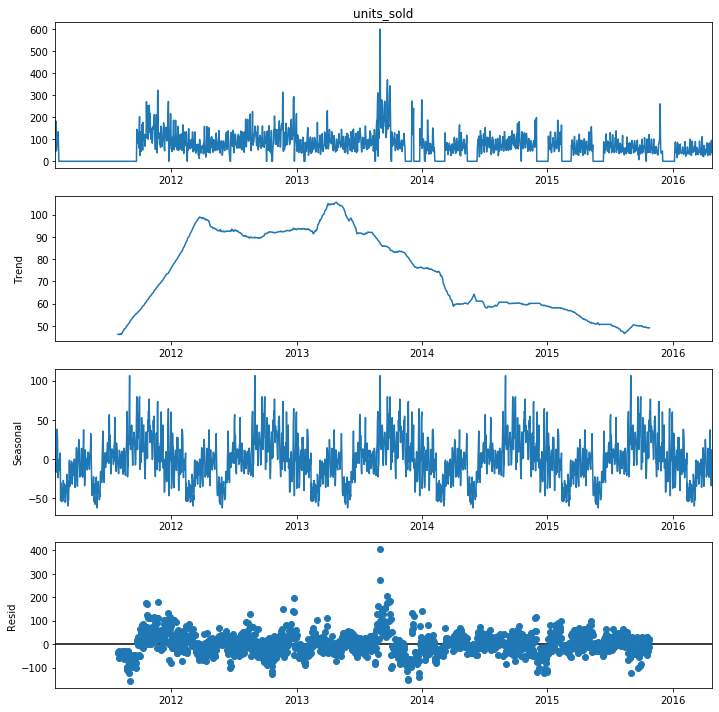

In [3]:
# view decomp
decomposition = seasonal_decompose(
    sales_long.set_index('date')['units_sold'],
    model='additive',
    period=365
)

fig = decomposition.plot()
fig.set_size_inches(10, 10)
plt.tight_layout()
plt.show()

# Feature engineering
Used in downstream machine learning models.

In [10]:
# convert date and sort observations by item, store, and date
sales_long['date'] = pd.to_datetime(sales_long['date'])

sales_long = sales_long.sort_values(
    ['item_id', 'store_id', 'date']
).reset_index(drop=True)

# calendar features
sales_long['day_of_week'] = sales_long['date'].dt.dayofweek
sales_long['day_of_month'] = sales_long['date'].dt.day
sales_long['week_of_year'] = (
    sales_long['date'].dt.isocalendar().week.astype('int8')
)
sales_long['month'] = sales_long['date'].dt.month
sales_long['year'] = sales_long['date'].dt.year
sales_long['is_weekend'] = (
    sales_long['day_of_week'] >= 5
).astype('int8')

# group sales by item and store
group_keys = ['item_id', 'store_id']
grouped_sales = sales_long.groupby(
    group_keys, sort=False
)['units_sold']

# lag features
lag_cols = []

for lag in [1, 7, 14, 28]:
    col = 'lag_' + str(lag)
    sales_long[col] = grouped_sales.shift(lag)
    lag_cols.append(col)

# calculate rolling features from prior observations
rolling_cols = []

for window in [7, 28, 56]:
    shifted_sales = grouped_sales.shift(1)

    rolling = (
        shifted_sales.groupby(
            [sales_long['item_id'], sales_long['store_id']],
            sort=False
        )
        .rolling(window=window, min_periods=window)
    )

    mean_col = 'rolling_mean_' + str(window)
    std_col = 'rolling_std_' + str(window)

    sales_long[mean_col] = (
        rolling.mean()
        .reset_index(level=[0, 1], drop=True)
        .reindex(sales_long.index)
    )

    sales_long[std_col] = (
        rolling.std()
        .reset_index(level=[0, 1], drop=True)
        .reindex(sales_long.index)
    )

    rolling_cols.extend([mean_col, std_col])

# flag missing lag and rolling features
feature_cols_to_fill = lag_cols + rolling_cols

for col in feature_cols_to_fill:
    sales_long[col + '_missing'] = (
        sales_long[col].isna().astype('int8')
    )

# fill missing features
sales_long[feature_cols_to_fill] = (
    sales_long[feature_cols_to_fill].fillna(0)
)

# Train/test

In [11]:
# split into train and test sets
# use 28 days to capture roughly 4 weeks of activity
test_days = 28

dates = sorted(sales_long['date'].unique())
test_start = dates[-test_days]

train = sales_long[sales_long['date'] < test_start].copy()
test = sales_long[sales_long['date'] >= test_start].copy()

# Seasonal-naive baseline
This model will be our baseline to which we'll compare all subsequent models.

seasonal-naive mae: 18.71
seasonal-naive rmse: 23.42
seasonal-naive wape: 36.82 %
seasonal-naive bias: -3.23 %


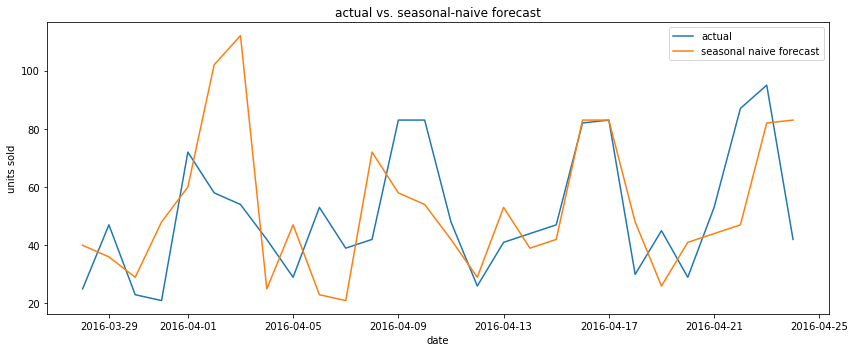

In [12]:
# create seasonal-naive forecast
# use sales from 7 days earlier to predict each test observation

naive_train = train[
    ['item_id', 'store_id', 'date', 'units_sold']
].copy()

naive_test = test[
    ['item_id', 'store_id', 'date', 'units_sold']
].copy()

# combine historical and test observations to construct lag features
naive_all = pd.concat(
    [naive_train, naive_test],
    ignore_index=True
).sort_values(['item_id', 'store_id', 'date'])

naive_all['naive_forecast'] = (
    naive_all.groupby(['item_id', 'store_id'])['units_sold']
    .shift(7)
)

# select forecasts for the same test observations
evaluation = naive_all[
    naive_all['date'] >= test_start
].copy()

# calculate metrics
errors = evaluation['units_sold'] - evaluation['naive_forecast']
errors = errors.dropna()

evaluation = evaluation.loc[errors.index]

mae = errors.abs().mean()
rmse = np.sqrt((errors ** 2).mean())

actual_total = evaluation['units_sold'].sum()

wape = (
    errors.abs().sum() / actual_total * 100
    if actual_total != 0 else np.nan
)

bias = (
    errors.sum() / actual_total * 100
    if actual_total != 0 else np.nan
)

# save metrics
result_dict['Seasonal Naive'] = {
    'MAE': mae,
    'RMSE': rmse,
    'WAPE': wape,
    'Bias': bias
}

print('seasonal-naive mae:', round(mae, 2))
print('seasonal-naive rmse:', round(rmse, 2))
print('seasonal-naive wape:', round(wape, 2), '%')
print('seasonal-naive bias:', round(bias, 2), '%')

# plot aggregate daily actual vs forecast
daily = (
    evaluation.groupby('date', as_index=False)
    [['units_sold', 'naive_forecast']]
    .sum()
)

plt.figure(figsize=(12, 5))

plt.plot(
    daily['date'].to_numpy(),
    daily['units_sold'].to_numpy(),
    label='actual'
)

plt.plot(
    daily['date'].to_numpy(),
    daily['naive_forecast'].to_numpy(),
    label='seasonal naive forecast'
)

plt.title('actual vs. seasonal-naive forecast')
plt.xlabel('date')
plt.ylabel('units sold')
plt.legend()
plt.tight_layout()
plt.show()

# ARIMA
ARIMA models use moving averages and past values to make predictions.  

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[7] intercept   : AIC=inf, Time=5.32 sec
 ARIMA(0,1,0)(0,0,0)[7] intercept   : AIC=19499.747, Time=0.07 sec
 ARIMA(1,1,0)(1,0,0)[7] intercept   : AIC=19249.844, Time=0.83 sec
 ARIMA(0,1,1)(0,0,1)[7] intercept   : AIC=19175.710, Time=0.89 sec
 ARIMA(0,1,0)(0,0,0)[7]             : AIC=19497.747, Time=0.05 sec
 ARIMA(0,1,1)(0,0,0)[7] intercept   : AIC=19300.325, Time=0.28 sec
 ARIMA(0,1,1)(1,0,1)[7] intercept   : AIC=inf, Time=2.21 sec
 ARIMA(0,1,1)(0,0,2)[7] intercept   : AIC=19140.914, Time=2.17 sec
 ARIMA(0,1,1)(1,0,2)[7] intercept   : AIC=inf, Time=4.68 sec
 ARIMA(0,1,0)(0,0,2)[7] intercept   : AIC=19385.950, Time=1.34 sec
 ARIMA(1,1,1)(0,0,2)[7] intercept   : AIC=18937.523, Time=2.50 sec
 ARIMA(1,1,1)(0,0,1)[7] intercept   : AIC=18955.877, Time=1.36 sec
 ARIMA(1,1,1)(1,0,2)[7] intercept   : AIC=inf, Time=5.28 sec
 ARIMA(1,1,1)(1,0,1)[7] intercept   : AIC=inf, Time=2.68 sec
 ARIMA(1,1,0)(0,0,2)[7] intercept   : AIC=19260.1

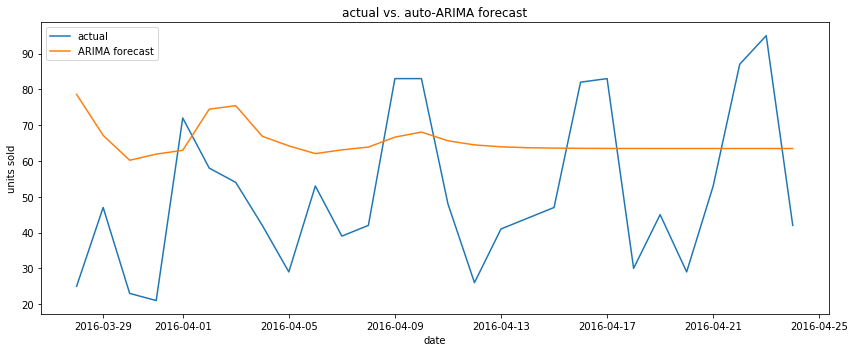

In [19]:
from pmdarima import auto_arima

# prepare training and test time series
arima_train = (
    train.sort_values('date')
    .set_index('date')['units_sold']
    .astype(float)
    .asfreq('D')
)

arima_test = (
    test.sort_values('date')
    .set_index('date')['units_sold']
    .astype(float)
    .asfreq('D')
)

# fill missing dates, if any
arima_train = arima_train.interpolate(method='time')
arima_test = arima_test.interpolate(method='time')

# select the best arima parameters using training data only
arima_model = auto_arima(
    arima_train,
    seasonal=True,
    m=7,
    stepwise=True,
    suppress_warnings=True,
    error_action='ignore',
    trace=True
)

print('selected ARIMA order:', arima_model.order)
print('selected seasonal order:', arima_model.seasonal_order)

# forecast the test period
arima_predictions = arima_model.predict(
    n_periods=len(arima_test)
)

arima_predictions = pd.Series(
    np.asarray(arima_predictions),
    index=arima_test.index
).clip(lower=0)

# calculate metrics
errors = arima_test - arima_predictions

mae = errors.abs().mean()
rmse = np.sqrt((errors ** 2).mean())

actual_total = arima_test.sum()

wape = (
    errors.abs().sum() / actual_total * 100
    if actual_total != 0 else np.nan
)

bias = (
    errors.sum() / actual_total * 100
    if actual_total != 0 else np.nan
)

# save metrics
result_dict['ARIMA'] = {
    'MAE': mae,
    'RMSE': rmse,
    'WAPE': wape,
    'Bias': bias
}

print('ARIMA MAE:', round(mae, 2))
print('ARIMA RMSE:', round(rmse, 2))
print('ARIMA WAPE:', round(wape, 2), '%')
print('ARIMA Bias:', round(bias, 2), '%')

# compare actual sales with forecast
plt.figure(figsize=(12, 5))

plt.plot(
    arima_test.index.to_numpy(),
    arima_test.to_numpy(),
    label='actual'
)

plt.plot(
    arima_predictions.index.to_numpy(),
    arima_predictions.to_numpy(),
    label='ARIMA forecast'
)

plt.title('actual vs. auto-ARIMA forecast')
plt.xlabel('date')
plt.ylabel('units sold')
plt.legend()
plt.tight_layout()
plt.show()

The model which was chosen by auto_arima is not capturing the two month seasonality.

## Examine model residuals
Four main assumptions:
1. Zero mean  
2. Constant variance (homoscedasticity)  
3. No autocorrelation  
4. Normality  

mean residual: -0.03573571839454027


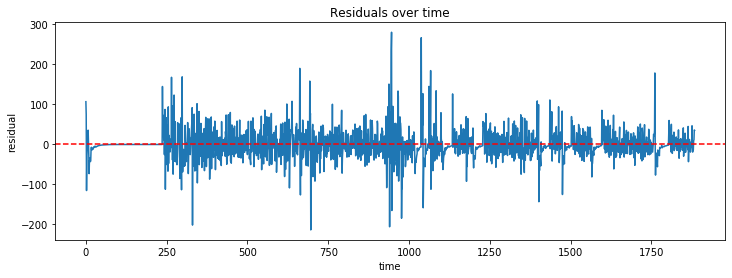

first-half variance: 1394.9603479996906
second-half variance: 1317.625328087883


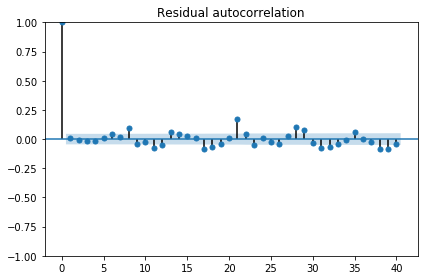

acorr_ljungbox results
      lb_stat     lb_pvalue
10  27.435586  2.221282e-03
20  80.580848  3.127867e-09
lag 10: reject null hypothesis - evidence of autocorrelation
lag 20: reject null hypothesis - evidence of autocorrelation


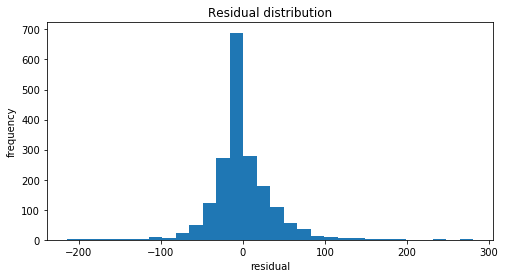

shapiro-wilk statistic: 0.8887689113616943
shapiro-wilk p-value: 7.860749981195714e-35
reject null hypothesis - evidence residuals are not normally distributed


In [14]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import numpy as np

# get in-sample residuals from the fitted arima_model
residuals = np.asarray(arima_model.resid())

# 1. zero mean
print('mean residual:', np.mean(residuals))

# 2. constant variance
plt.figure(figsize=(12, 4))
plt.plot(residuals)
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuals over time')
plt.xlabel('time')
plt.ylabel('residual')
plt.show()

# compare variance across the first and second halves
midpoint = len(residuals) // 2
print('first-half variance:', np.var(residuals[:midpoint]))
print('second-half variance:', np.var(residuals[midpoint:]))

# 3. no autocorrelation
plot_acf(residuals, lags=40)
plt.title('Residual autocorrelation')
plt.tight_layout()
plt.show()

# null hypothesis: residuals have no autocorrelation
print('acorr_ljungbox results')
ljung_box = acorr_ljungbox(residuals, lags=[10, 20], return_df=True)
print(ljung_box)

for lag, p_value in zip(ljung_box.index, ljung_box['lb_pvalue']):
    if p_value < 0.05:
        print('lag {}: reject null hypothesis - evidence of autocorrelation'.format(lag))
    else:
        print('lag {}: fail to reject null hypothesis - no significant autocorrelation detected'.format(lag))

# 4. normality
plt.figure(figsize=(8, 4))
plt.hist(residuals, bins=30)
plt.title('Residual distribution')
plt.xlabel('residual')
plt.ylabel('frequency')
plt.show()

# null hypothesis: residuals follow a normal distribution
shapiro_stat, shapiro_p = shapiro(residuals)
print('shapiro-wilk statistic:', shapiro_stat)
print('shapiro-wilk p-value:', shapiro_p)

if shapiro_p < 0.05:
    print('reject null hypothesis - evidence residuals are not normally distributed')
else:
    print('fail to reject null hypothesis - no significant evidence against normality')

The residuals conclude that the ARIMA models cannot capture enough signal in the data.  
Let's try an ML model.

# Machine Learning

In [15]:
# define features and target
feature_cols = [
    'item_id',
    'store_id',
    'dept_id',
    'cat_id',
    'state_id',
    'day_of_week',
    'day_of_month',
    'week_of_year',
    'month',
    'year',
    'is_weekend',
    'lag_1',
    'lag_7',
    'lag_14',
    'lag_28',
    'rolling_mean_7',
    'rolling_mean_28',
    'rolling_mean_56',
    'rolling_std_7',
    'rolling_std_28',
    'rolling_std_56'
]

target_col = 'units_sold'

X_train = train[feature_cols].copy()
y_train = train[target_col]

X_test = test[feature_cols].copy()
y_test = test[target_col]

print('Training rows:', len(train))
print('Testing rows:', len(test))
print('Training dates:', train['date'].min().date(), 'to', train['date'].max().date())
print('Testing dates:', test['date'].min().date(), 'to', test['date'].max().date())

# encode categorical variables
categorical_cols = [
    'item_id',
    'store_id',
    'dept_id',
    'cat_id',
    'state_id'
]

for col in categorical_cols:
    X_train[col] = X_train[col].astype('category')
    X_test[col] = X_test[col].astype('category')

Training rows: 1885
Testing rows: 28
Training dates: 2011-01-29 to 2016-03-27
Testing dates: 2016-03-28 to 2016-04-24


# LightGBM
LightGBM can learn complex relationships between features that a traditional time-series model like ARIMA may not capture well.

2026-10-24 19:01:48.030954

test performance
MAE: 14.4422
RMSE: 17.3381
WAPE: 28.42%
Forecast bias: 12.03%
2026-10-24 19:01:48.795549


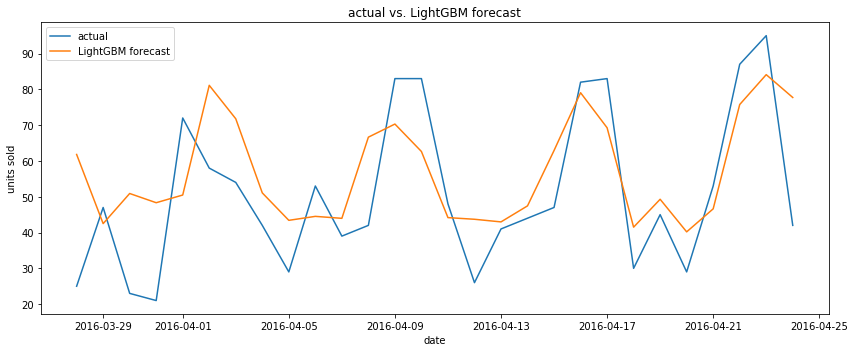

In [20]:
print(dt.datetime.now())

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# initialize the model
lgbm_model = LGBMRegressor(
    objective='regression',
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgbm_categorical_cols = [
    'item_id', 'store_id', 'dept_id', 'cat_id', 'state_id'
]

# train the model
lgbm_model.fit(
    X_train,
    y_train,
    categorical_feature=lgbm_categorical_cols
)

# generate predictions
lgbm_predictions = lgbm_model.predict(X_test)

# calculate evaluation metrics
lgbm_mae = mean_absolute_error(y_test, lgbm_predictions)
lgbm_rmse = np.sqrt(mean_squared_error(y_test, lgbm_predictions))

lgbm_actual_total = np.sum(y_test)
lgbm_wape = (
    np.sum(np.abs(y_test - lgbm_predictions)) / lgbm_actual_total * 100
    if lgbm_actual_total != 0 else np.nan
)

lgbm_bias = (
    np.sum(lgbm_predictions - y_test) / lgbm_actual_total * 100
    if lgbm_actual_total != 0 else np.nan
)

# save test metrics to result_dict
result_dict['LightGBM'] = {
    'MAE': round(lgbm_mae, 2),
    'RMSE': round(lgbm_rmse, 2),
    'WAPE': round(lgbm_wape, 2),
    'Bias': round(lgbm_bias, 2)
}

print('\ntest performance')
print(f'MAE: {lgbm_mae:.4f}')
print(f'RMSE: {lgbm_rmse:.4f}')
print(f'WAPE: {lgbm_wape:.2f}%')
print(f'Forecast bias: {lgbm_bias:.2f}%')
print(dt.datetime.now())

# aggregate actual sales and predictions by date
lgbm_plot_data = pd.DataFrame({
    'date': test['date'].to_numpy(),
    'actual': y_test.to_numpy(),
    'predicted': lgbm_predictions
})

lgbm_daily_results = (
    lgbm_plot_data
    .groupby('date')[['actual', 'predicted']]
    .sum()
)

# plot actual vs. predicted sales
plt.figure(figsize=(12, 5))
plt.plot(
    test['date'].to_numpy(),
    y_test.to_numpy(),
    label='actual'
)
plt.plot(
    test['date'].to_numpy(),
    lgbm_predictions,
    label='LightGBM forecast'
)
plt.title('actual vs. LightGBM forecast')
plt.xlabel('date')
plt.ylabel('units sold')
plt.legend()
plt.tight_layout()
plt.show()

LightGBM performs better than ARIMA.

## Feature importance

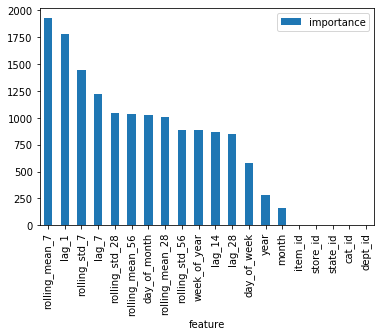

In [26]:
# inspect feature importance
# technique uses split importance: how many times a feature was used to split observations across the trees
importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': lgbm_model.feature_importances_
}).sort_values('importance', ascending=False)

importance.head(20).set_index('feature').plot(kind='bar')

# XGBoost
Another flavor of gradient boosting machine, like LightGBM.  


seasonal-naive baseline (lag_7)
MAE:  18.7143
WAPE: 36.82%

XGBoost test performance
MAE: 14.6881
RMSE: 18.3703
WAPE: 28.90%
Forecast bias: 12.17%

mean sales per row
Actual:    50.8214
Predicted: 57.0065


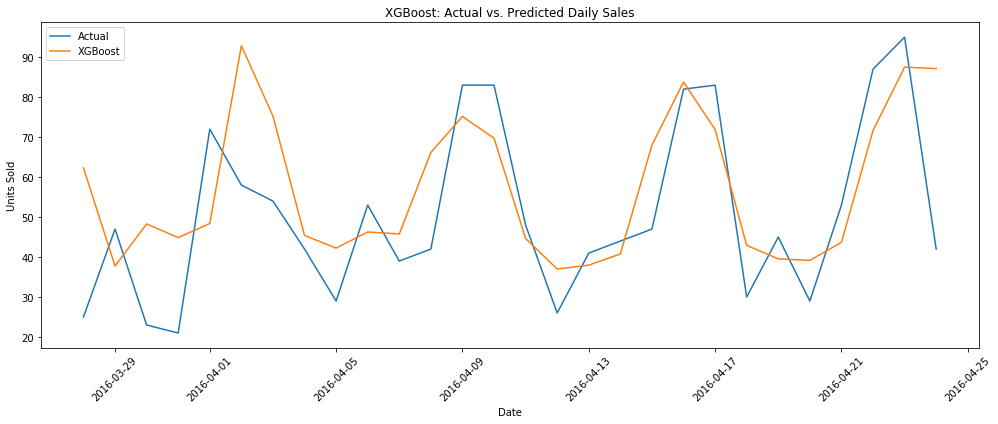

In [28]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# align categorical levels between training and test data
xgb_categorical_cols = [
    'item_id',
    'store_id',
    'dept_id',
    'cat_id',
    'state_id'
]

for xgb_col in xgb_categorical_cols:
    xgb_categories = X_train[xgb_col].cat.categories.union(
        X_test[xgb_col].cat.categories
    )
    X_train[xgb_col] = X_train[xgb_col].cat.set_categories(xgb_categories)
    X_test[xgb_col] = X_test[xgb_col].cat.set_categories(xgb_categories)

# initialize the model
xgb_model = XGBRegressor(
    objective='reg:squarederror',
    tree_method='hist',
    enable_categorical=True,
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1
)

# train the model
xgb_model.fit(X_train, y_train)

# generate predictions
xgb_y_pred = xgb_model.predict(X_test)

# calculate evaluation metrics
xgb_actual = np.asarray(y_test)
xgb_actual_total = np.sum(xgb_actual)
xgb_errors = xgb_actual - xgb_y_pred

xgb_mae = mean_absolute_error(xgb_actual, xgb_y_pred)
xgb_rmse = np.sqrt(mean_squared_error(xgb_actual, xgb_y_pred))

xgb_wape = (
    np.sum(np.abs(xgb_errors)) / np.sum(np.abs(xgb_actual)) * 100
    if np.sum(np.abs(xgb_actual)) != 0 else np.nan
)

xgb_bias = (
    np.sum(xgb_y_pred - xgb_actual) / xgb_actual_total * 100
    if xgb_actual_total != 0 else np.nan
)

# evaluate seasonal-naive baseline using lag-7
if 'lag_7' in X_test.columns:
    xgb_baseline_pred = X_test['lag_7'].to_numpy()

    xgb_baseline_mae = mean_absolute_error(
        xgb_actual, xgb_baseline_pred
    )
    xgb_baseline_wape = (
        np.sum(np.abs(xgb_actual - xgb_baseline_pred))
        / np.sum(np.abs(xgb_actual)) * 100
        if np.sum(np.abs(xgb_actual)) != 0 else np.nan
    )

    print('\nseasonal-naive baseline (lag_7)')
    print(f'MAE:  {xgb_baseline_mae:.4f}')
    print(f'WAPE: {xgb_baseline_wape:.2f}%')

# save test metrics to result_dict
result_dict['XGBoost'] = {
    'MAE': round(xgb_mae, 2),
    'RMSE': round(xgb_rmse, 2),
    'WAPE': round(xgb_wape, 2),
    'Bias': round(xgb_bias, 2)
}

print('\nXGBoost test performance')
print(f'MAE: {xgb_mae:.4f}')
print(f'RMSE: {xgb_rmse:.4f}')
print(f'WAPE: {xgb_wape:.2f}%')
print(f'Forecast bias: {xgb_bias:.2f}%')

print('\nmean sales per row')
print(f'Actual:    {np.mean(xgb_actual):.4f}')
print(f'Predicted: {np.mean(xgb_y_pred):.4f}')

# compare total daily actual sales with predictions
xgb_daily_comparison = (
    pd.DataFrame({
        'date': test['date'].to_numpy(),
        'actual': xgb_actual,
        'predicted': xgb_y_pred
    })
    .groupby('date', as_index=False)[['actual', 'predicted']]
    .sum()
)

# convert plot inputs to numpy arrays to avoid pandas indexing warnings
xgb_plot_dates = xgb_daily_comparison['date'].to_numpy()
xgb_plot_actual = xgb_daily_comparison['actual'].to_numpy()
xgb_plot_predicted = xgb_daily_comparison['predicted'].to_numpy()

plt.figure(figsize=(14, 6))
plt.plot(
    xgb_plot_dates,
    xgb_plot_actual,
    label='Actual'
)
plt.plot(
    xgb_plot_dates,
    xgb_plot_predicted,
    label='XGBoost'
)
plt.title('XGBoost: Actual vs. Predicted Daily Sales')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Results

In [29]:
display(pd.DataFrame(result_dict).T)

,MAE,RMSE,WAPE,Bias
Seasonal Naive,18.714286,23.420077,36.823612,-3.232607
ARIMA,23.995203,26.121773,47.214736,-28.472227
LightGBM,14.440000,17.340000,28.420000,12.030000
XGBoost,14.690000,18.370000,28.900000,12.170000


LightGBM, with the lowest RMSE and positive bias, is the winner.

In [ ]:
print('done')